# Molecular features
Notebook with code to calculate the molecular descriptors (using DeepChem) and to analyze the main features:
- size
- solubility
- lipophilicity
- flexibility
- saturation
- polarity

## Imports

In [1]:
from amp import load, work_in_outputs
work_in_outputs("01_molecular-features")
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['svg.fonttype'] = 'none'

import numpy as np
from rdkit import Chem
import deepchem as dc

Skipped loading some Pytorch utilities, missing a dependency. No module named 'torch'


No normalization for SPS. Feature removed!


No normalization for AvgIpc. Feature removed!


Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'


Skipped loading some PyTorch models, missing a dependency. No module named 'torch'


...

Skipped loading modules with pytorch-geometric dependency, missing a dependency. No module named 'torch'


Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'torch'


Skipped loading some Jax models, missing a dependency. No module named 'jax'


Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


This module requires PyTorch to be installed.


In [2]:
# Import list of smiles
df = load("compounds").drop(columns="Semi_synthetic")
print(df.shape)
df.head()

(253, 7)


,ID,Name,Scaffold,Type,Subtype,SMILES,DOI_Structures
0,AQ001,"6,6′-oxybis(1,3,8-trihydroxy-2-((S)-1-methoxyh...",anthraquinone,dimer,complex,OC1=CC(OC2=CC(O)=C(C(C(C(O)=C([C@@H](OC)CCCCC)...,10.1016/j.fitote.2018.11.015
1,AQ002,"6,6′-oxybis(1,3,8-trihydroxy-2-((S)-1-hydroxyh...",anthraquinone,dimer,complex,O=C1C2=C(C(C3=C1C=C(C=C3O)OC4=CC(O)=C5C(C(C6=C...,10.1016/j.fitote.2018.11.015
2,AQ003,1′-O-methylaverantin,anthraquinone,monomer,simple,OC1=CC(O)=C(C2=C1)C(C3=C(C2=O)C=C(O)C([C@@H](O...,10.1016/j.fitote.2018.11.015
3,AQ004,Averantin,anthraquinone,monomer,simple,OC1=CC(O)=C(C2=C1)C(C3=C(C2=O)C=C(O)C([C@@H](O...,10.1016/j.fitote.2018.11.015
4,AQ005,Averythrin,anthraquinone,monomer,simple,OC1=CC(O)=C(C2=C1)C(C3=C(C2=O)C=C(O)C(/C=C/CCC...,10.1016/j.fitote.2018.11.015


In [3]:
# fomatting Scaffolds series
df['Scaffold'] = [x.strip() for x in df['Scaffold']]
df['Scaffold'] = df['Scaffold'].astype('category')
df['Scaffold'].unique()

['anthraquinone', 'benzophenone', 'diphenyl-ether', 'xanthone']
Categories (4, object): ['anthraquinone', 'benzophenone', 'diphenyl-ether', 'xanthone']

In [4]:
# drop not needed columns
df.drop(columns=['Name','DOI_Structures'],inplace=True)

In [5]:
# import previously save dataframe
df_features = load("molecular_features")

## Calculate molecular descriptors

In [6]:
# Label values using the featurizer's actual emitted descriptor order.
smiles = df.SMILES
featurizer = dc.feat.RDKitDescriptors()
features = pd.DataFrame(
    featurizer.featurize(smiles),
    columns=list(featurizer.reqd_properties),
    index=df.index,
)
assert features.shape == (len(df), len(featurizer.reqd_properties))


In [7]:
# Import features calculated with SwissAdme
descriptors = load("swissadme_descriptors")
print(descriptors.shape)
descriptors.head()

(253, 30)


,ID,Scaffold,Formula,MW,#Heavy atoms,#Aromatic heavy atoms,Fraction Csp3,#Rotatable bonds,#H-bond acceptors,#H-bond donors,...,ESOL Solubility (mol/l),ESOL Class,Ali Log S,Ali Solubility (mg/ml),Ali Solubility (mol/l),Ali Class,Silicos-IT LogSw,Silicos-IT Solubility (mg/ml),Silicos-IT Solubility (mol/l),Silicos-IT class
0,AQ001,anthraquinone,C42H42O13,754.78,55,24,0.33,14,13,6,...,6.620000e-10,Poorly soluble,-12.78,1.250000e-10,1.660000e-13,Insoluble,-10.73,1.390000e-08,1.840000e-11,Insoluble
1,AQ002,anthraquinone,C40H38O13,726.72,53,24,0.30,12,13,8,...,6.790000e-10,Poorly soluble,-13.27,3.870000e-11,5.330000e-14,Insoluble,-9.37,3.080000e-07,4.240000e-10,Poorly soluble
2,AQ003,anthraquinone,C21H22O7,386.40,28,12,0.33,6,7,4,...,2.040000e-05,Moderately soluble,-6.33,1.800000e-04,4.650000e-07,Poorly soluble,-5.06,3.370000e-03,8.730000e-06,Moderately soluble
3,AQ004,anthraquinone,C20H20O7,372.37,27,12,0.30,5,7,5,...,2.060000e-05,Moderately soluble,-6.57,9.930000e-05,2.670000e-07,Poorly soluble,-4.37,1.600000e-02,4.290000e-05,Moderately soluble
4,AQ005,anthraquinone,C20H18O6,354.35,26,12,0.20,4,6,4,...,1.090000e-05,Moderately soluble,-6.66,7.790000e-05,2.200000e-07,Poorly soluble,-4.59,9.050000e-03,2.550000e-05,Moderately soluble


In [8]:
# Merge features with df

df_features = pd.concat([df, features], axis=1)
                                                                                                                              

In [9]:
# Normalize join keys on both sides; reject duplicate or unmatched keys.
keys = ['ID', 'Scaffold']
for frame in (df, df_features, descriptors):
    for key in keys:
        frame[key] = frame[key].astype('string').str.strip()
    assert not frame[keys].isna().any().any(), 'Missing descriptor join key'
    assert not frame.duplicated(keys).any(), 'Duplicate descriptor join key'
expected_ids = set(df['ID'])
assert len(df) == 253 and len(expected_ids) == 246

def merge_descriptors(frame):
    merged = frame.merge(descriptors, on=keys, how='left',
                         validate='one_to_one', indicator=True)
    unmatched = merged.loc[merged['_merge'] != 'both', keys]
    assert unmatched.empty, f'Unmatched descriptor keys: {unmatched.to_dict("records")}'
    assert len(merged) == len(frame) == 253
    assert set(merged['ID']) == expected_ids
    return merged.drop(columns='_merge')

df_descriptors = merge_descriptors(df)
print(f'Initial df: {df.shape}; descriptors: {descriptors.shape}; merged: {df_descriptors.shape}')


Initial df: (253, 5); descriptors: (253, 30); merged: (253, 33)


In [10]:
# Preserve every scaffold assignment and compound when adding SwissADME data.
print(f"Initial dataframe: {df_features.shape}")
df_features = merge_descriptors(df_features)
print(f"Merged dataframe: {df_features.shape}")


Initial dataframe: (253, 215)
Merged dataframe: (253, 243)


In [11]:
# fomatting Scaffolds series
df_features['Scaffold'] = [x.strip() for x in df_features['Scaffold']]
df_features['Scaffold'] = df_features['Scaffold'].astype('category')
df_features['Scaffold'].unique()

['anthraquinone', 'benzophenone', 'diphenyl-ether', 'xanthone']
Categories (4, object): ['anthraquinone', 'benzophenone', 'diphenyl-ether', 'xanthone']

## Features analysis

In [12]:
scaffold_order=['anthraquinone','diphenyl-ether','xanthone','benzophenone']

### Size

#### Compare size from RDkit and SwissAdme

In [13]:
# MW from RDkit
MolWt = pd.concat([
    df_features.groupby('Scaffold').MolWt.mean(),
    df_features.groupby('Scaffold').MolWt.std(),
    df_features.groupby('Scaffold').MolWt.quantile(0.75) - df_features.groupby('Scaffold').MolWt.quantile(0.25)],
    axis=1)

MolWt.columns = ['mean', 'std', 'iqr']
MolWt.head()

,mean,std,iqr
Scaffold,,,
anthraquinone,399.407807,135.930466,125.07950
benzophenone,356.748923,56.031312,68.89000
diphenyl-ether,482.959865,179.331190,191.30875
xanthone,413.866400,156.335782,316.30900


In [14]:
# MW from SwissAdme
MolWt = pd.concat([
    df_features.groupby('Scaffold').MW.mean(),
    df_features.groupby('Scaffold').MW.std(),
    df_features.groupby('Scaffold').MW.quantile(0.75) - df_features.groupby('Scaffold').MW.quantile(0.25)],
    axis=1)

MolWt.columns = ['mean', 'std', 'iqr']
MolWt.head()

,mean,std,iqr
Scaffold,,,
anthraquinone,399.403109,135.928672,125.080
benzophenone,356.744615,56.031846,68.890
diphenyl-ether,482.955833,179.330602,191.315
xanthone,413.862400,156.333685,316.310


#### Plot size

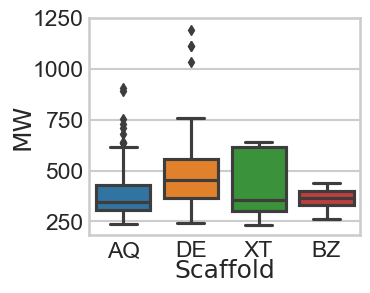

In [15]:
# plot MW
sns.set_context("talk")
sns.set_style("whitegrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }
sns.color_palette("deep")

f, ax = plt.subplots(figsize=(3.5, 3))
ax.set_box_aspect(0.8)

sns.boxplot(data = df_features, x='Scaffold', y= 'MolWt',order=scaffold_order)

ax.tick_params(axis='both', which='major', pad=-5)
#ax.set_ylim([220,10])
ax.set_yticks([250,500,750,1000,1250])
ax.set_ylabel("MW", fontdict=font,labelpad=-1)
ax.set_xticklabels(['AQ','DE','XT','BZ'])
ax.set_xlabel("Scaffold", fontdict=font, labelpad=-1)

plt.savefig('plots/box_mw.svg')

### Log P

#### Compare different Log P

In [16]:
diffLogP = pd.concat([
    df_features.Scaffold,
    df_features.MolLogP,
    df_features.iLOGP,
    df_features.XLOGP3,
    df_features.WLOGP,
    df_features.MLOGP,
    df_features['Silicos-IT Log P']], 
    axis=1)

diffLogP.columns = ['Scaffold','MolLogP','iLOGP', 'XLOGP3', 'WLOGP', 'MLOGP','Silicos-IT Log P']
diffLogP['Scaffold'] = diffLogP['Scaffold'].astype('category')

diffLogP['Mean Log P'] = diffLogP.mean(axis=1,numeric_only=True)
diffLogP

,Scaffold,MolLogP,iLOGP,XLOGP3,WLOGP,MLOGP,Silicos-IT Log P,Mean Log P
0,anthraquinone,7.79890,6.11,8.35,7.15,0.32,8.15,6.313150
1,anthraquinone,6.49070,4.90,8.38,5.84,-0.02,7.01,5.433450
2,anthraquinone,3.55220,2.95,4.02,3.23,0.43,3.79,2.995367
3,anthraquinone,2.89810,2.54,4.03,2.57,0.21,3.24,2.581350
4,anthraquinone,3.48780,2.40,4.52,3.38,0.93,3.83,3.091300
...,...,...,...,...,...,...,...,...
248,xanthone,2.37142,2.04,2.81,2.37,0.57,2.47,2.105237
249,xanthone,3.00640,2.89,3.37,3.01,1.07,2.74,2.681067
250,xanthone,3.79752,3.32,4.11,3.65,1.67,4.58,3.521253
251,xanthone,3.01500,3.15,3.34,3.02,0.77,2.77,2.677500


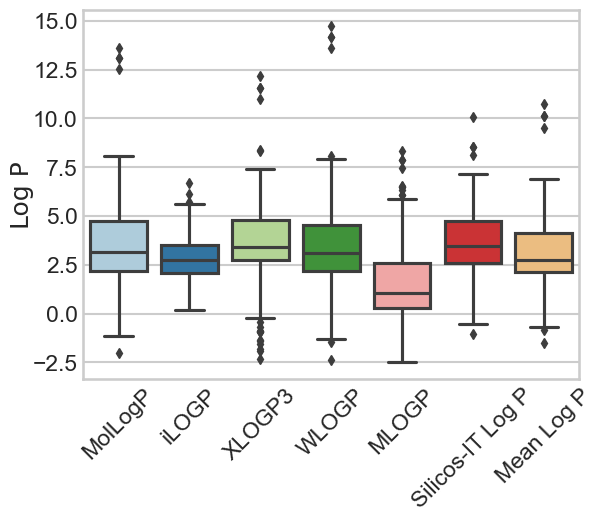

In [17]:
# plot Log P
sns.set_context("talk")
sns.set_style("whitegrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }
sns.set_palette("Paired")

f, ax = plt.subplots()


sns.boxplot(data = diffLogP)

ax.tick_params(axis='both', which='major', pad=-5)
ax.set_ylabel("Log P", fontdict=font,labelpad=-1)

plt.xticks(rotation = 45)

plt.savefig('plots/box_different-logP.svg')

In [18]:
diffLogP_means = pd.concat([
    df_features.groupby('Scaffold').MolLogP.mean(),
    df_descriptors.groupby('Scaffold').iLOGP.mean(),
    df_descriptors.groupby('Scaffold').XLOGP3.mean(),
    df_descriptors.groupby('Scaffold').WLOGP.mean(),
    df_descriptors.groupby('Scaffold').MLOGP.mean(),
    df_descriptors.groupby('Scaffold')['Silicos-IT Log P'].mean(),], 
    axis=1)

diffLogP_means.columns = ['MolLogP','iLOGP', 'XLOGP3', 'WLOGP', 'MLOGP','Silicos-IT Log P']
diffLogP_means.head()

,MolLogP,iLOGP,XLOGP3,WLOGP,MLOGP,Silicos-IT Log P
Scaffold,,,,,,
anthraquinone,2.185546,2.491513,2.487311,2.046134,0.188992,2.956050
benzophenone,2.818288,2.353077,3.615385,2.794615,1.447692,3.220000
diphenyl-ether,5.508300,3.270417,5.275833,5.518854,3.888333,4.589271
xanthone,2.975218,2.968400,3.134400,2.854400,0.687600,3.151200


In [19]:
# Update dataframe with mean log P
df_features['Mean Log P'] = diffLogP['Mean Log P'].copy()


#### Mean Log P analysis

In [20]:
MolLogP = pd.concat([
    df_features.groupby('Scaffold')['Mean Log P'].mean(),
    df_features.groupby('Scaffold')['Mean Log P'].median(),
    df_features.groupby('Scaffold')['Mean Log P'].std(),
    df_features.groupby('Scaffold')['Mean Log P'].quantile(0.75) - df_features.groupby('Scaffold')['Mean Log P'].quantile(0.25)],
    axis=1)

MolLogP.columns = ['mean', 'median' ,'std', 'iqr']
MolLogP.head()

,mean,median,std,iqr
Scaffold,,,,
anthraquinone,2.059258,2.255920,1.277431,1.517302
benzophenone,2.708176,2.515170,0.955443,0.812733
diphenyl-ether,4.675168,4.718285,1.827256,2.798973
xanthone,2.628536,2.657570,0.653848,0.659787


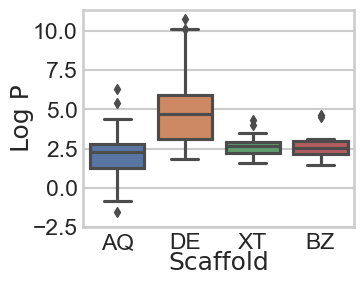

In [21]:
# plot Log P
sns.set_context("talk")
sns.set_style("whitegrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }
sns.set_palette("deep")

f, ax = plt.subplots(figsize=(3.5, 3))
ax.set_box_aspect(0.8)

sns.boxplot(data = df_features, x='Scaffold', y= 'Mean Log P', order=scaffold_order)

ax.tick_params(axis='both', which='major', pad=-5)
#ax.set_ylim([-0.6,6.1])
ax.set_yticks([-2.5,0,2.5,5,7.5,10])
ax.set_ylabel("Log P", fontdict=font,labelpad=-1)

ax.set_xticklabels(['AQ','DE','XT','BZ'])
ax.set_xlabel("Scaffold", fontdict=font, labelpad=-1)

plt.savefig('plots/box_logP-scaffold.svg')

### Fraction Csp3

In [22]:
FractionCSP3 = pd.concat([
    df_features.groupby('Scaffold').FractionCSP3.mean(),
    df_features.groupby('Scaffold').FractionCSP3.median(),
    df_features.groupby('Scaffold').FractionCSP3.std(),
    df_features.groupby('Scaffold').FractionCSP3.quantile(0.75) - df_features.groupby('Scaffold').FractionCSP3.quantile(0.25)],
    axis=1)

FractionCSP3.columns = ['mean','median','std', 'iqr']
FractionCSP3.head()

,mean,median,std,iqr
Scaffold,,,,
anthraquinone,0.271676,0.227273,0.157420,0.181818
benzophenone,0.181421,0.176471,0.059848,0.045752
diphenyl-ether,0.146687,0.142857,0.132740,0.229167
xanthone,0.265089,0.307692,0.114860,0.196970


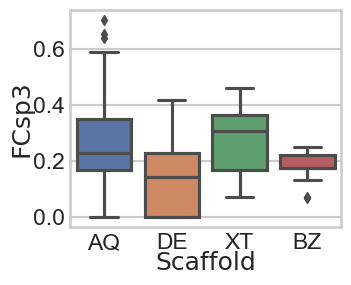

In [23]:
# plot Fraction Csp3
sns.set_context("talk")
sns.set_style("whitegrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }
sns.set_palette("deep")

f, ax = plt.subplots(figsize=(3.5, 3))
ax.set_box_aspect(0.8)

sns.boxplot(data = df_features, x='Scaffold', y= 'FractionCSP3',order=scaffold_order)

ax.tick_params(axis='both', which='major', pad=-5)
#ax.set_ylim([-0.6,6.1])
#ax.set_yticks([0,0.2,0.4,0.6])
ax.set_ylabel("FCsp3", fontdict=font, labelpad=-1)

ax.set_xticklabels(['AQ','DE','XT','BZ'])
ax.set_xlabel("Scaffold", fontdict=font, labelpad=-1)

plt.savefig('plots/box_fcsp3-scaffold.svg')

In [24]:
df_features[(df_features['TPSA_x']>150) & (df_features['Scaffold'] == 'xanthone')]

,ID,Scaffold,Type,Subtype,SMILES,AvgIpc,BCUT2D_CHGHI,BCUT2D_CHGLO,BCUT2D_LOGPHI,BCUT2D_LOGPLOW,...,ESOL Class,Ali Log S,Ali Solubility (mg/ml),Ali Solubility (mol/l),Ali Class,Silicos-IT LogSw,Silicos-IT Solubility (mg/ml),Silicos-IT Solubility (mol/l),Silicos-IT class,Mean Log P
235,XT026,xanthone,dimer,complex,OC1=CC=CC([C@@H]([C@]23C4=C(O)[C@@H](C(C)=C3)C...,3.168060,2.628231,-2.449403,2.634244,-2.612301,...,Moderately soluble,-7.08,0.000051,8.240000e-08,Poorly soluble,-5.18,0.004070,6.610000e-06,Moderately soluble,2.691717
236,XT027,xanthone,dimer,complex,OC1=CC=CC([C@H](OC(C)=O)[C@]23C4=C(O)[C@@H](C(...,3.203443,2.625516,-2.453722,2.636759,-2.586220,...,Poorly soluble,-8.49,0.000002,3.270000e-09,Poorly soluble,-6.92,0.000078,1.220000e-07,Poorly soluble,4.352617
237,XT028,xanthone,dimer,complex,OC1=CC=CC([C@@H]([C@]23C4=C(O)[C@@H](C(C)=C3)C...,3.165058,2.635468,-2.449647,2.638313,-2.613971,...,Moderately soluble,-7.08,0.000051,8.240000e-08,Poorly soluble,-5.18,0.004070,6.610000e-06,Moderately soluble,2.721717
238,XT029,xanthone,dimer,complex,OC1=CC=CC([C@@H]([C@]23C4=C(O)[C@@H](C(C)=C3)C...,3.165058,2.635468,-2.449647,2.638313,-2.613971,...,Moderately soluble,-7.08,0.000051,8.240000e-08,Poorly soluble,-5.18,0.004070,6.610000e-06,Moderately soluble,2.753383
239,XT030,xanthone,derivative,complex,OC1=CC=CC([C@@H]([C@]23C4=C(O)[C@@H](C(C)=C3)C...,3.320174,2.608337,-2.449029,2.631611,-2.576026,...,Moderately soluble,-6.54,0.000179,2.900000e-07,Poorly soluble,-5.99,0.000632,1.030000e-06,Moderately soluble,2.969867
240,XT032,xanthone,derivative,complex,OC1=CC=CC([C@@H]([C@]23C4=C(O)[C@@H](C(C)=C3)C...,3.171244,2.603903,-2.449062,2.634065,-2.579759,...,Moderately soluble,-6.38,0.000262,4.130000e-07,Poorly soluble,-5.11,0.004890,7.710000e-06,Moderately soluble,2.464883
241,XT033,xanthone,derivative,complex,OC1=CC=CC([C@@H]([C@]23C4=C(O)[C@@H](C(C)=C3)C...,3.171244,2.603903,-2.449062,2.634065,-2.579759,...,Moderately soluble,-6.38,0.000262,4.130000e-07,Poorly soluble,-5.11,0.004890,7.710000e-06,Moderately soluble,2.303217
242,XT034,xanthone,dimer,complex,OC(C[C@H](C)[C@H]1O)=C2[C@]1(OC3=CC=C(C4=C(O[C...,3.011689,2.645070,-2.455150,2.550214,-2.634012,...,Poorly soluble,-8.25,0.000004,5.590000e-09,Poorly soluble,-4.17,0.043200,6.760000e-05,Moderately soluble,2.155700


### Rotatable Bonds

In [25]:
NumRotatableBonds = pd.concat([
    df_features.groupby('Scaffold').NumRotatableBonds.mean(),
    df_features.groupby('Scaffold').NumRotatableBonds.median(),
    df_features.groupby('Scaffold').NumRotatableBonds.std(),
    df_features.groupby('Scaffold').NumRotatableBonds.quantile(0.75) - df_features.groupby('Scaffold').NumRotatableBonds.quantile(0.25)],
    axis=1)

NumRotatableBonds.columns = ['mean', 'median', 'std', 'iqr']
NumRotatableBonds.head()

,mean,median,std,iqr
Scaffold,,,,
anthraquinone,2.243697,1.0,2.421536,2.0
benzophenone,4.153846,4.0,1.344504,2.0
diphenyl-ether,4.343750,4.0,2.524941,3.0
xanthone,2.280000,2.0,1.541644,1.0


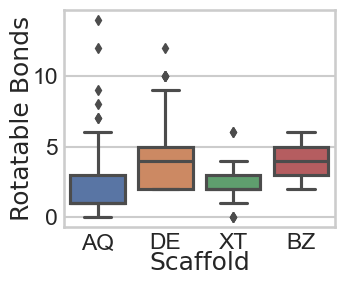

In [26]:
# plot Rotatable Bonds
sns.set_context("talk")
sns.set_style("whitegrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }

f, ax = plt.subplots(figsize=(3.5, 3))
ax.set_box_aspect(0.8)

sns.boxplot(data = df_features, x='Scaffold', y= 'NumRotatableBonds', order=scaffold_order)

ax.tick_params(axis='both', which='major', pad=-5)
#ax.set_ylim([-0.6,6.1])
#ax.set_yticks([0,0.2,0.4,0.6])
ax.set_ylabel("Rotatable Bonds", fontdict=font, labelpad=-1)

ax.set_xticklabels(['AQ','DE','XT','BZ'])
ax.set_xlabel("Scaffold", fontdict=font, labelpad=-1)

plt.savefig('plots/box_rb-scaffold.svg')

### TPSA

In [27]:
# comapre TPSA calculated by RdKit and SwissAdme
df_features.loc[:,df_features.columns.str.startswith('TPSA')]

,TPSA_x,TPSA_y
0,217.35,217.35
1,239.35,239.35
2,124.29,124.29
3,135.29,135.29
4,115.06,115.06
...,...,...
248,90.90,90.90
249,78.13,78.13
250,79.90,79.90
251,87.36,87.36


In [28]:
TPSA = pd.concat([
    df_features.groupby('Scaffold').TPSA_x.mean(),
    df_features.groupby('Scaffold').TPSA_x.median(),
    df_features.groupby('Scaffold').TPSA_x.std(),
    df_features.groupby('Scaffold').TPSA_x.quantile(0.75) - df_features.groupby('Scaffold').TPSA_x.quantile(0.25)],
    axis=1)

TPSA.columns = ['mean', 'median','std', 'iqr']
TPSA.head()

,mean,median,std,iqr
Scaffold,,,,
anthraquinone,125.593193,115.060,41.405010,52.28
benzophenone,108.757692,113.290,13.766595,12.77
diphenyl-ether,71.877604,54.305,42.699777,82.06
xanthone,123.571600,96.220,55.914434,96.99


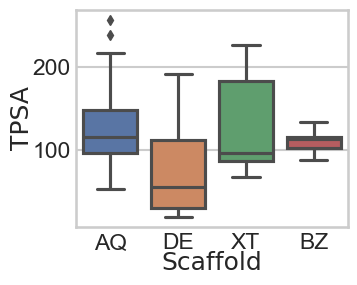

In [29]:
# plot TPSA
sns.set_context("talk")
sns.set_style("whitegrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }

f, ax = plt.subplots(figsize=(3.5, 3))
ax.set_box_aspect(0.8)

sns.boxplot(data = df_features, x='Scaffold', y= 'TPSA_x',order=scaffold_order)

ax.tick_params(axis='both', which='major', pad=-5)
#ax.set_ylim([-0.6,6.1])
#ax.set_yticks([0,0.2,0.4,0.6])
ax.set_ylabel("TPSA", fontdict=font, labelpad=-1)

ax.set_xticklabels(['AQ','DE','XT','BZ'])
ax.set_xlabel("Scaffold", fontdict=font, labelpad=-1)

plt.savefig('plots/box_tpsa-scaffold.svg')

### Log S

#### Compare Log S

In [30]:
df_features.loc[:,df_features.columns.str.contains('Log S')]

,ESOL Log S,Ali Log S
0,-9.18,-12.78
1,-9.17,-13.27
2,-4.69,-6.33
3,-4.69,-6.57
4,-4.96,-6.66
...,...,...
248,-3.76,-4.38
249,-4.34,-4.69
250,-4.69,-5.49
251,-4.41,-4.85


In [31]:
diffLogS = pd.concat([
    df_features['Scaffold'],
    df_features['ESOL Log S'],
    df_features['Ali Log S']], 
    axis=1)

diffLogS.columns = ['Scaffold','ESOL Log S','Ali Log S']
diffLogS['Scaffold'] = diffLogS['Scaffold'].astype('category')

diffLogS['Mean Log S'] = diffLogS.mean(axis=1,numeric_only=True)
diffLogS

,Scaffold,ESOL Log S,Ali Log S,Mean Log S
0,anthraquinone,-9.18,-12.78,-10.980
1,anthraquinone,-9.17,-13.27,-11.220
2,anthraquinone,-4.69,-6.33,-5.510
3,anthraquinone,-4.69,-6.57,-5.630
4,anthraquinone,-4.96,-6.66,-5.810
...,...,...,...,...
248,xanthone,-3.76,-4.38,-4.070
249,xanthone,-4.34,-4.69,-4.515
250,xanthone,-4.69,-5.49,-5.090
251,xanthone,-4.41,-4.85,-4.630


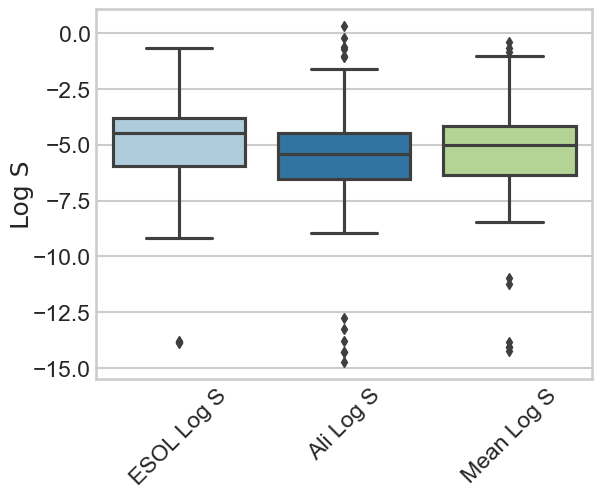

In [32]:
# plot Log S
sns.set_context("talk")
sns.set_style("whitegrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }
sns.set_palette("Paired")

f, ax = plt.subplots()


sns.boxplot(data = diffLogS)

ax.tick_params(axis='both', which='major', pad=-5)
ax.set_ylabel("Log S", fontdict=font,labelpad=-1)

plt.xticks(rotation = 45)

plt.savefig('plots/box_different-logS.svg')

In [33]:
# Update dataframe with mean log P
df_features['Mean Log S'] = diffLogS['Mean Log S'].copy()

#### Mean Log S analysis

In [34]:
LogS = pd.concat([
    df_features.groupby('Scaffold')['Mean Log S'].mean(),
    df_features.groupby('Scaffold')['Mean Log S'].median(),
    df_features.groupby('Scaffold')['Mean Log S'].std(),
    df_features.groupby('Scaffold')['Mean Log S'].quantile(0.75) - df_features.groupby('Scaffold')['ESOL Log S'].quantile(0.25)],
    axis=1)

LogS.columns = ['mean', 'median','std', 'iqr']
LogS.head()

,mean,median,std,iqr
Scaffold,,,,
anthraquinone,-4.412983,-4.3550,1.783290,0.98000
benzophenone,-4.973846,-4.5850,1.093104,0.21500
diphenyl-ether,-6.401094,-6.1125,2.039691,2.62125
xanthone,-4.963000,-4.9550,1.340568,1.11000


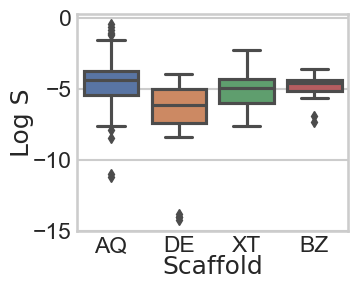

In [35]:
# plot Log S
sns.set_context("talk")
sns.set_style("whitegrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }
sns.set_palette("deep")

f, ax = plt.subplots(figsize=(3.5, 3))
ax.set_box_aspect(0.8)

sns.boxplot(data = df_features, x='Scaffold', y= 'Mean Log S',order=scaffold_order)

ax.tick_params(axis='both', which='major', pad=-5)
#ax.set_ylim([-0.6,6.1])
ax.set_yticks([0,-5,-10,-15])
ax.set_ylabel("Log S", fontdict=font, labelpad=-1)

ax.set_xticklabels(['AQ','DE','XT','BZ'])
ax.set_xlabel("Scaffold", fontdict=font, labelpad=-1)

plt.savefig('plots/box_logs-scaffold.svg')

## Save dataframe

In [36]:
df_features.drop(columns="TPSA_y", inplace=True)
df_features.rename(columns={"TPSA_x": "TPSA"}, inplace=True)


In [37]:
# A compound assigned to two scaffolds must have the same descriptors in both rows.
descriptor_columns = list(featurizer.reqd_properties)
assert not df_features.groupby('ID')[descriptor_columns].nunique(dropna=False).gt(1).any().any()
df_features.drop_duplicates(subset=['ID'], inplace=True)
assert len(df_features) == 246
assert set(df_features['ID']) == expected_ids


In [38]:
# percentage of insoluble compounds
df_features[df_features['Mean Log S'] < -4].shape[0] / df_features.shape[0]

0.8170731707317073

In [39]:
df_features.columns[df_features.columns.str.startswith('fr')]

Index(['fr_Al_COO', 'fr_Al_OH', 'fr_Al_OH_noTert', 'fr_ArN', 'fr_Ar_COO',
       'fr_Ar_N', 'fr_Ar_NH', 'fr_Ar_OH', 'fr_COO', 'fr_COO2', 'fr_C_O',
       'fr_C_O_noCOO', 'fr_C_S', 'fr_HOCCN', 'fr_Imine', 'fr_NH0', 'fr_NH1',
       'fr_NH2', 'fr_N_O', 'fr_Ndealkylation1', 'fr_Ndealkylation2',
       'fr_Nhpyrrole', 'fr_SH', 'fr_aldehyde', 'fr_alkyl_carbamate',
       'fr_alkyl_halide', 'fr_allylic_oxid', 'fr_amide', 'fr_amidine',
       'fr_aniline', 'fr_aryl_methyl', 'fr_azide', 'fr_azo', 'fr_barbitur',
       'fr_benzene', 'fr_benzodiazepine', 'fr_bicyclic', 'fr_diazo',
       'fr_dihydropyridine', 'fr_epoxide', 'fr_ester', 'fr_ether', 'fr_furan',
       'fr_guanido', 'fr_halogen', 'fr_hdrzine', 'fr_hdrzone', 'fr_imidazole',
       'fr_imide', 'fr_isocyan', 'fr_isothiocyan', 'fr_ketone',
       'fr_ketone_Topliss', 'fr_lactam', 'fr_lactone', 'fr_methoxy',
       'fr_morpholine', 'fr_nitrile', 'fr_nitro', 'fr_nitro_arom',
       'fr_nitro_arom_nonortho', 'fr_nitroso', 'fr_oxazole', 'fr

In [40]:
df_features[df_features['fr_COO'] != 0].shape

(32, 244)

In [41]:
df_features[(df_features['fr_NH0'] != 0) | (df_features['fr_NH1'] != 0) | (df_features['fr_Ar_NH'] != 0)].shape

(8, 244)

In [42]:
df_features.to_csv("molecular_features.csv", index=False)